# CS5284 Project Data EDA

**Group 4 — LLM-Assisted Product Categorisation on a Co-purchase Graph**

This notebook follows the dataset and research questions in `Project Proposal/project_plan_contract_group4.docx`. It retrieves **TAPE's ogbn-products subset**, checks its integrity, and starts exploratory analysis of product text, categories, graph structure, and splits. The proposal's expectations (54,025 products, approximately 74k co-purchase edges, 47 category IDs) are hypotheses to verify, not computed results.

Run cells from top to bottom. Downloads are cached under `data/TAPE` in this repository; optional exports go to `data/TAPE/eda`. No model training, LLM calls, or data cleaning that changes node identities is performed.

### Questions for this first pass

1. Do the released text, labels, graph, and split masks agree?
2. How imbalanced are the categories, and which are absent from individual splits?
3. How complete and repetitive are titles and descriptions?
4. How many products have few neighbours, and do linked products share labels?
5. What data issues should inform the extraction pilot and later experiments?

## 1. Sources and retrieval plan

TAPE is a method with several released datasets; this project uses its **ogbn-products subset**. Do not substitute the full `PygNodePropPredDataset('ogbn-products')` or SNAP Amazon graphs: their node sets differ.

Verified against the official repository on 14 October 2026:

| Artifact | Official repository path | Purpose |
|---|---|---|
| Product text | `dataset/ogbn_products_orig/ogbn-products_subset.csv` | `title`, `content`, and original product identifiers |
| Graph | `dataset/ogbn_products/ogbn-products_subset.pt` | Serialized PyG graph, labels, features, and split masks |
| Optional explanations | README's ogbn-products LLM-response Google Drive link | Later arms G/H; not required for initial EDA |

Sources: [TAPE README](https://github.com/XiaoxinHe/TAPE), [official product loader](https://github.com/XiaoxinHe/TAPE/blob/d9881f7e277823d0c3a56851c6ccd0412adc773f/core/data_utils/load_products.py), [official response loader](https://github.com/XiaoxinHe/TAPE/blob/d9881f7e277823d0c3a56851c6ccd0412adc773f/core/data_utils/load.py).

We pin downloads to commit `d9881f7e277823d0c3a56851c6ccd0412adc773f`. The text loader consumes CSV rows in file order; original `nid` values must not be used directly as subset indices. The graph loader symmetrises `adj_t`; below we count unique undirected, non-self edges explicitly so reverse entries do not double the edge count.

## 2. Environment

Use a Python kernel with NumPy, pandas, Matplotlib, SciPy, PyTorch, PyG, and `torch-sparse`. The release contains a PyG object with a `torch_sparse.SparseTensor`, so `torch-sparse` is needed even for EDA. A CPU environment is sufficient.

If needed, run `%pip install numpy pandas matplotlib scipy torch torch-geometric` in a separate cell. Install a **matching `torch-sparse` wheel** using the [official PyG installation instructions](https://pytorch-geometric.readthedocs.io/en/latest/install/installation.html), selecting your PyTorch version and CPU/CUDA build; restart the kernel afterwards. TAPE's original environment is also documented in its README. Installation is not run automatically.

Use the Graph dependency setup cells below to check versions and install matching extension wheels in the active kernel.

**Project environment:** use the CS5284 course environment `gnn_course` with the packages in the repository's `requirements.txt` (torch-scatter, torch-sparse and the other extras): run `pip install -r requirements.txt` from the repository root, or `%pip install -r ../../requirements.txt` from this folder, then restart the kernel. Keep `INSTALL_GRAPH_DEPENDENCIES = False` for this environment. The proposal document referenced above is external to this repository and is not needed to locate or load the dataset.

The earlier import error occurred because `torch_sparse` and `torch_scatter` were absent from the selected kernel; installing `torch-geometric` alone does not install these optional extensions. This dataset requires `torch_sparse.SparseTensor` to deserialize its graph.


### Graph dependency setup (run before the imports)

This checks the active kernel's PyTorch version and selects the corresponding PyG wheel page. To resolve `No module named torch_sparse`, set `INSTALL_GRAPH_DEPENDENCIES = True` and run the next cell once. It installs into this notebook's kernel using `%pip`. **Restart the kernel after installation**, set the flag back to `False`, and rerun the notebook.

PyG uses a `major.minor.0` wheel page for supported PyTorch 2.x versions, including patch releases. Installation includes `torch-scatter`, which `torch-sparse` may need. Binary-only installation prevents an unexpected source build. If no matching wheel is available, inspect the printed Python/PyTorch/CUDA versions and consult the [official PyG installation guide](https://pytorch-geometric.readthedocs.io/en/latest/install/installation.html).


In [36]:
import time
import importlib

for package in ["numpy", "pandas", "matplotlib.pyplot", "scipy.sparse"]:
    start = time.perf_counter()
    print(f"Loading {package}...", flush=True)
    importlib.import_module(package)
    print(f"Done in {time.perf_counter() - start:.2f}s", flush=True)

Loading numpy...
Done in 0.00s
Loading pandas...
Done in 0.00s
Loading matplotlib.pyplot...
Done in 0.00s
Loading scipy.sparse...
Done in 0.00s


In [37]:
import sys
import importlib.util

INSTALL_GRAPH_DEPENDENCIES = False  # Set True once to install missing graph packages.

try:
    import torch
except ImportError as exc:
    raise ImportError("PyTorch is missing from this kernel. Run %pip install torch, restart the kernel, then retry.") from exc

print("Python:", sys.version.split()[0])
print("Kernel executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
version_parts = torch.__version__.split("+")[0].split(".")
wheel_version = ".".join(version_parts[:2] + ["0"])
build = "cpu" if torch.version.cuda is None else "cu" + torch.version.cuda.replace(".", "")
wheel_url = f"https://data.pyg.org/whl/torch-{wheel_version}+{build}.html"
print("Matching wheel page:", wheel_url)
missing = [name for name in ["torch_geometric", "torch_scatter", "torch_sparse"]
           if importlib.util.find_spec(name) is None]
print("Missing packages:", missing or "none")

if INSTALL_GRAPH_DEPENDENCIES:
    get_ipython().run_line_magic("pip", "install torch-geometric")
    get_ipython().run_line_magic("pip", f"install --only-binary=:all: torch-scatter torch-sparse -f {wheel_url}")
    print("Restart the kernel, set INSTALL_GRAPH_DEPENDENCIES=False, then rerun the notebook.")
elif missing:
    print("Set INSTALL_GRAPH_DEPENDENCIES=True above and run this cell to install.")


Python: 3.11.7
Kernel executable: <project>\.venv\Scripts\python.exe
PyTorch: 2.1.2+cpu
PyTorch CUDA build: None
Matching wheel page: https://data.pyg.org/whl/torch-2.1.0+cpu.html
Missing packages: none


In [38]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import urllib.request
import warnings
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from IPython.display import display

# Graph dependencies required by TAPE's serialized graph.
try:
    import torch
    import torch_geometric
    import torch_sparse
except ImportError as exc:
    raise ImportError(
        "Missing graph dependency. Run the Graph dependency setup cell with "
        "INSTALL_GRAPH_DEPENDENCIES=True, restart the kernel, then rerun."
    ) from exc

SEED = 5284
pd.set_option('display.max_colwidth', 160)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False})

# Works when Jupyter starts in the project root or anywhere beneath it.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents]
                     if (p / 'requirements.txt').is_file()
                     and (p / 'notebooks' / '0_eda').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter inside the cs5284-product-gnn repository (for example, notebooks/0_eda).')
REQUIREMENTS_PATH = PROJECT_ROOT / 'requirements.txt'
DATA_DIR = PROJECT_ROOT / 'data' / 'TAPE'
DATA_DIR.mkdir(parents=True, exist_ok=True)
COMMIT = 'd9881f7e277823d0c3a56851c6ccd0412adc773f'
BASE_URL = f'https://raw.githubusercontent.com/XiaoxinHe/TAPE/{COMMIT}'
ARTIFACTS = {
    'text': ('dataset/ogbn_products_orig/ogbn-products_subset.csv', 37554824),
    'graph': ('dataset/ogbn_products/ogbn-products_subset.pt', 25507847),
}
print('Project root:', PROJECT_ROOT)
print('Requirements:', REQUIREMENTS_PATH)
print('Cache:', DATA_DIR)
print('Python:', platform.python_version())

Project root: <repo>
Requirements: <repo>\requirements-eda.txt
Cache: <repo>\data\TAPE
Python: 3.11.7


## 3. Download and record provenance

The two core files total about 63 MB. This cell requires internet access on first run. A partial download is kept separate and atomically renamed only after its size is checked; existing files are reused after the same check. SHA-256 values are recorded for reproducibility (local fingerprints, not independently published checksums).

If internet access is unavailable, download the two pinned raw URLs in a browser and place the files in the printed cache directory, then rerun the cell.

In [39]:
def sha256_file(path):
    digest = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

provenance = []
paths = {}
for key, (relative_path, expected_bytes) in ARTIFACTS.items():
    url = f'{BASE_URL}/{relative_path}'
    destination = DATA_DIR / Path(relative_path).name
    if not destination.exists():
        partial = destination.with_suffix(destination.suffix + '.part')
        print('Downloading:', url)
        request = urllib.request.Request(url, headers={'User-Agent': 'CS5284-EDA'})
        with urllib.request.urlopen(request, timeout=120) as response, partial.open('wb') as out:
            while chunk := response.read(1024 * 1024):
                out.write(chunk)
        if partial.stat().st_size != expected_bytes:
            raise ValueError(f'Incomplete or changed artifact: {partial}')
        partial.replace(destination)
    if destination.stat().st_size != expected_bytes:
        raise ValueError(f'Unexpected file size: {destination}. Check the pinned source.')
    paths[key] = destination
    provenance.append({'artifact': key, 'url': url, 'bytes': destination.stat().st_size,
                       'sha256': sha256_file(destination), 'commit': COMMIT})
provenance = pd.DataFrame(provenance)
display(provenance)
provenance.to_json(DATA_DIR / 'download_manifest.json', orient='records', indent=2)

,artifact,url,bytes,sha256,commit
0,text,https://raw.githubusercontent.com/XiaoxinHe/TAPE/d9881f7e277823d0c3a56851c6ccd0412adc773f/dataset/ogbn_products_orig/ogbn-products_subset.csv,37554824,87b3733d24563efda4aaf2e03b42f3acba9a61daa9e5c3d40c8f25f822f45137,d9881f7e277823d0c3a56851c6ccd0412adc773f
1,graph,https://raw.githubusercontent.com/XiaoxinHe/TAPE/d9881f7e277823d0c3a56851c6ccd0412adc773f/dataset/ogbn_products/ogbn-products_subset.pt,25507847,70bc85fcbc20c65637729abda51f996bb46fdbfc98145d07ec3855a2ba1779e4,d9881f7e277823d0c3a56851c6ccd0412adc773f


## 4. Load the release and inspect its schema

The `.pt` file is a legacy serialized Python object. `weights_only=False` is required by modern PyTorch and can execute pickle code: load only the official pinned artifact above, not an arbitrary replacement. We load onto CPU and inspect the object before assuming a schema.

Keep text rows in release order. `node_id` below is the contiguous **subset** index; `nid` (if present) is retained as original provenance. Equal row counts and unique IDs are useful checks, but do not independently prove semantic alignment; row-order alignment follows the official loader.

`uid` in the `text` df refers to the Amazon ASIN. This can be used to join to the Amazon-3M metadata to obtain more features like price, brand, sales ranking etc.

In [40]:
try:
    import torch
    import torch_geometric
    import torch_sparse
except ImportError as exc:
    raise ImportError('Install PyTorch, PyG and matching torch-sparse; see Section 2.') from exc

text = pd.read_csv(paths['text'])
graph = torch.load(paths['graph'], map_location='cpu', weights_only=False)
print("graph:", graph)
print('CSV columns:', text.columns.tolist())

print("\ntext df:")
display(text.head())
required = {'title', 'content'}
if not required.issubset(text.columns):
    raise ValueError(f'Missing text fields: {required - set(text.columns)}')

def as_numpy(value):
    return value.detach().cpu().numpy() if hasattr(value, 'detach') else np.asarray(value)

n = int(graph.num_nodes)
labels = as_numpy(graph.y).reshape(-1)
assert len(text) == n == len(labels), 'Text/graph/label lengths differ.'
assert np.isfinite(labels).all() and np.equal(labels, labels.astype(int)).all()
labels = labels.astype(np.int64)
assert ((labels >= 0) & (labels < 47)).all(), 'Category ID outside expected range.'

# Create nodes df
nodes = text.copy()
nodes.insert(0, 'node_id', np.arange(n))
nodes['label'] = labels
print("\nnodes df:")
nodes.head()

graph: Data(num_nodes=54025, x=[54025, 100], y=[54025, 1], adj_t=[54025, 54025, nnz=74420], train_mask=[54025], val_mask=[54025], test_mask=[54025], n_id=[54025], e_id=[74420], input_id=[128], batch_size=128, n_asin=[54025])
CSV columns: ['uid', 'nid', 'title', 'content']

text df:


,uid,nid,title,content
0,B00JXMX35K,1324660,"Aimee Gowns Original Bra-less Nursing Gown (X-Large, Fuchsia)",The one that started it all! The nightgown's modern design features a split front to help facilitate easy access to the breast for the baby. Simply pull asi...
1,B000XQHYFU,1670226,Casio DR-270TM 2-Color Professional Desktop Printing Calculator,Heavy duty printing
2,B00B67RO9Q,1780321,NaN,NaN
3,B005JN9CKM,2447868,Muay Thai Shorts-Black,"for Size Chart, please see attached photos. Improved design with 3 inches long split side seams for unrestricted range of motion. lightweight satin. Made of..."
4,B00CU9YBVS,1940019,Smatree&reg; Chest Belt/Strap Harness Mount+ Aluminum Thumbscrew+J-Hook for Gopro Hero3+ Hero3 Hero2 1Cameras Adjustable,1. Smatree chest strap is fully adjustable to fit all sizes.2. Chest Harness for your quick-release HERO camera.3. Makes it easy to capture immersive video ...



nodes df:


,node_id,uid,nid,title,content,label
0,0,B00JXMX35K,1324660,"Aimee Gowns Original Bra-less Nursing Gown (X-Large, Fuchsia)",The one that started it all! The nightgown's modern design features a split front to help facilitate easy access to the breast for the baby. Simply pull asi...,11
1,1,B000XQHYFU,1670226,Casio DR-270TM 2-Color Professional Desktop Printing Calculator,Heavy duty printing,18
2,2,B00B67RO9Q,1780321,NaN,NaN,4
3,3,B005JN9CKM,2447868,Muay Thai Shorts-Black,"for Size Chart, please see attached photos. Improved design with 3 inches long split side seams for unrestricted range of motion. lightweight satin. Made of...",11
4,4,B00CU9YBVS,1940019,Smatree&reg; Chest Belt/Strap Harness Mount+ Aluminum Thumbscrew+J-Hook for Gopro Hero3+ Hero3 Hero2 1Cameras Adjustable,1. Smatree chest strap is fully adjustable to fit all sizes.2. Chest Harness for your quick-release HERO camera.3. Makes it easy to capture immersive video ...,12


In [41]:
for identifier in ['nid', 'uid']:
    if identifier in nodes:
        assert nodes[identifier].notna().all(), f'Missing {identifier}'
        assert nodes[identifier].is_unique, f'Duplicate {identifier}; inspect alignment.'
# Cross-check original identifiers when the graph exposes aligned subset metadata.
for column, attribute in [('nid', 'n_id'), ('uid', 'n_asin')]:
    graph_ids = getattr(graph, attribute, None)
    if column in nodes and graph_ids is not None:
        graph_ids = as_numpy(graph_ids).reshape(-1)
        if len(graph_ids) == n:
            assert np.array_equal(nodes[column].astype(str).to_numpy(), graph_ids.astype(str)), f'{column} order differs from graph {attribute}.'
        else:
            warnings.warn(f'{attribute} has {len(graph_ids)} entries; cannot directly verify subset IDs.')
print('Nodes:', n, '| Observed classes:', nodes.label.nunique())
if n != 54025:
    warnings.warn(f'Proposal expects 54,025 nodes; release contains {n:,}. Investigate.')

Nodes: 54025 | Observed classes: 42


In [42]:
print(labels)
print(len(set(labels)))
print(text.shape)

[11 18  4 ...  4  4  4]
42
(54025, 4)


### Identify the product category labels

Load OGB's `labelidx2productcategory.csv.gz` to map numeric labels to category names. The complete task has 47 possible IDs; this subset contains 42. This lookup does not require Amazon metadata or the full OGB graph.

The small file (628 bytes) is cached at `data/TAPE/labelidx2productcategory.csv.gz`. If absent, download a commit-pinned copy from the [TAG_datasets mirror](https://huggingface.co/datasets/WFRaain/TAG_datasets/blob/69c8f9bcf5c21b5e3932213ec45c23f5aa6d3cd3/products/labelidx2productcategory.csv.gz), verified against its published SHA-256. This is a mirrored OGB mapping, not a category inferred from product text. An original OGB copy can also be placed at the same path; the expected bytes must match.

The table shows all 47 IDs, category names, product counts, and whether each appears in this subset. `nodes['label_name']` is for interpretation; training labels and node order are unchanged. Keep category names out of product text sent to an extraction LLM.


In [43]:
LABEL_MAPPING_PATH = DATA_DIR / 'labelidx2productcategory.csv.gz'
LABEL_MAPPING_URL = (
    'https://huggingface.co/datasets/WFRaain/TAG_datasets/resolve/'
    '69c8f9bcf5c21b5e3932213ec45c23f5aa6d3cd3/products/labelidx2productcategory.csv.gz'
)
LABEL_MAPPING_SHA256 = '4616ab3a47f3d92fc4b256627bcd320c06cec9a2b49d3d6b4428b1c2687f5ef4'
if not LABEL_MAPPING_PATH.exists():
    request = urllib.request.Request(LABEL_MAPPING_URL, headers={'User-Agent': 'CS5284-EDA'})
    try:
        with urllib.request.urlopen(request, timeout=60) as response:
            mapping_bytes = response.read(4097)
    except OSError as exc:
        raise RuntimeError(
            f'Download the small mapping file from {LABEL_MAPPING_URL} in a browser '
            f'and save it to {LABEL_MAPPING_PATH}, then rerun this cell.'
        ) from exc
    if hashlib.sha256(mapping_bytes).hexdigest() != LABEL_MAPPING_SHA256:
        raise ValueError('Downloaded label mapping checksum differs from the pinned source.')
    partial = LABEL_MAPPING_PATH.with_suffix('.gz.part')
    partial.write_bytes(mapping_bytes)
    partial.replace(LABEL_MAPPING_PATH)
if hashlib.sha256(LABEL_MAPPING_PATH.read_bytes()).hexdigest() != LABEL_MAPPING_SHA256:
    raise ValueError('Cached label mapping checksum differs from the pinned source; inspect the file.')

label_mapping = pd.read_csv(LABEL_MAPPING_PATH)
required_columns = {'label idx', 'product category'}
if not required_columns.issubset(label_mapping.columns):
    raise ValueError(f'Unexpected label mapping columns: {label_mapping.columns.tolist()}')
label_mapping = label_mapping.rename(columns={'label idx': 'label', 'product category': 'label_name'})
if (label_mapping.label.duplicated().any()
        or set(label_mapping.label) != set(range(47))
        or label_mapping.label_name.isna().any()):
    raise ValueError('Expected exactly one named category for each of the 47 OGB IDs.')
label_names = label_mapping.set_index('label')['label_name']
nodes['label_name'] = nodes['label'].map(label_names)
assert nodes.label_name.notna().all(), 'A subset label has no category name.'
label_summary = label_names.to_frame().join(nodes.label.value_counts().rename('products'))
label_summary['products'] = label_summary.products.fillna(0).astype(int)
label_summary['present_in_subset'] = label_summary.products.gt(0)
label_summary['fraction_of_subset'] = label_summary.products / n
label_summary = label_summary.sort_index()
print(f'Observed classes: {nodes.label.nunique()} / {len(label_names)} possible OGB IDs')
print('Products:', n)
with pd.option_context('display.max_rows', 47):
    display(label_summary)
print('Categories absent from this subset:')
display(label_summary.loc[~label_summary.present_in_subset, ['label_name']])
display(nodes[['node_id', 'uid', 'title', 'label', 'label_name']].head(10))


Observed classes: 42 / 47 possible OGB IDs
Products: 54025


,label_name,products,present_in_subset,fraction_of_subset
label,,,,
0,Home & Kitchen,2721,True,0.050366
1,Health & Personal Care,3994,True,0.073929
2,Beauty,3718,True,0.068820
3,Sports & Outdoors,4605,True,0.085238
4,Books,10956,True,0.202795
5,"Patio, Lawn & Garden",649,True,0.012013
6,Toys & Games,3441,True,0.063693
7,CDs & Vinyl,2682,True,0.049644
8,Cell Phones & Accessories,3019,True,0.055882


Categories absent from this subset:


,label_name
label,
29,Luxury Beauty
33,Purchase Circles
44,Buy a Kindle
45,Furniture & decoration
46,MISSING


,node_id,uid,title,label,label_name
0,0,B00JXMX35K,"Aimee Gowns Original Bra-less Nursing Gown (X-Large, Fuchsia)",11,"Clothing, Shoes & Jewelry"
1,1,B000XQHYFU,Casio DR-270TM 2-Color Professional Desktop Printing Calculator,18,Office Products
2,2,B00B67RO9Q,NaN,4,Books
3,3,B005JN9CKM,Muay Thai Shorts-Black,11,"Clothing, Shoes & Jewelry"
4,4,B00CU9YBVS,Smatree&reg; Chest Belt/Strap Harness Mount+ Aluminum Thumbscrew+J-Hook for Gopro Hero3+ Hero3 Hero2 1Cameras Adjustable,12,Electronics
5,5,B0017K1KZ6,12 Schick Intuition Plus Cartridges for Sensitive Skin with 1 Bonus Razor - Enhanced Pivoting - Fragrance Free - Value Pak,1,Health & Personal Care
6,6,B00ESM41W4,"Cable Matters 2-Pack, Gold Plated 3.5mm Stereo Audio Cable in Black 6 Feet",12,Electronics
7,7,B003WMJ03G,"NCAA Alabama Crimson Tide Southpaw Backpack, Black",3,Sports & Outdoors
8,8,B002KFR628,"Gratiae Organics Replenishing Eye Serum, 1.02 Ounce",2,Beauty
9,9,B008QT20MI,Farkle Score Pad 5.5&quot; x 8.5&quot; 50-Sheets Notepad,18,Office Products


## 5. Verify the released train/validation/test split

Preserve the graph's masks for all experiment arms. Reject overlapping masks and unexpected multiple-split matrices; do not silently create a new random split. Unassigned nodes are reported explicitly. In this transductive task, edges across splits are expected; labels of validation/test nodes must not enter training or extraction prompts.

In [44]:
print("Train:")
print(len(graph.train_mask))
print(graph.train_mask)

print("\nTest:")
print(len(graph.test_mask))
print(graph.test_mask)

Train:
54025
tensor([False, False, False,  ...,  True, False, False])

Test:
54025
tensor([ True,  True,  True,  ..., False,  True,  True])


In [45]:
split_masks = {}
for split, attribute in [('train', 'train_mask'), ('valid', 'val_mask'), ('test', 'test_mask')]:
    raw = getattr(graph, attribute, None)
    if raw is None:
        raise ValueError(f'Released graph lacks {attribute}; inspect graph before proceeding.')
    mask = as_numpy(raw)
    if mask.shape == (n, 1):
        mask = mask[:, 0]
    if mask.shape != (n,) or mask.dtype != np.bool_:
        raise ValueError(f'{attribute} must be a boolean mask of length {n}; got {mask.shape}/{mask.dtype}')
    split_masks[split] = mask
membership = np.stack(list(split_masks.values()), axis=1).sum(axis=1)
assert (membership <= 1).all(), 'Splits overlap.'
nodes['split'] = 'unassigned'
for split, mask in split_masks.items():
    nodes.loc[mask, 'split'] = split
    assert mask.any(), f'Empty {split} split'
split_summary = nodes.groupby('split').size().rename('nodes').to_frame()
split_summary['fraction'] = split_summary.nodes / n
display(split_summary)
if (membership == 0).any():
    warnings.warn(f'{(membership == 0).sum():,} nodes have no split assignment.')

,nodes,fraction
split,,
test,37745,0.698658
train,14708,0.272244
valid,1572,0.029098


## 6. Class balance and split coverage

Category names come from the verified OGB mapping loaded in Section 4. Check all 47 possible IDs even if some are absent from the subset. Imbalance motivates reporting macro-F1 alongside accuracy. Test-set label statistics are descriptive diagnostics; do not use them to tune models or prompts.

,nodes,label_name,fraction,split_test,split_train,split_valid
label,,,,,,
0,2721,Home & Kitchen,0.050366,1784,848,89
1,3994,Health & Personal Care,0.073929,2497,1361,136
2,3718,Beauty,0.068820,2552,1022,144
3,4605,Sports & Outdoors,0.085238,3604,869,132
4,10956,Books,0.202795,6556,4017,383
5,649,"Patio, Lawn & Garden",0.012013,385,240,24
6,3441,Toys & Games,0.063693,2302,1043,96
7,2682,CDs & Vinyl,0.049644,1753,846,83
8,3019,Cell Phones & Accessories,0.055882,1738,1154,127


Absent category IDs: [29, 33, 44, 45, 46]
Largest/smallest observed class ratio: 10956.0
Training majority category: 4
Validation majority accuracy: 0.2436386768447837
Saved chart to: <repo>\notebooks\EDA\EDA results\product_counts_by_category.jpg


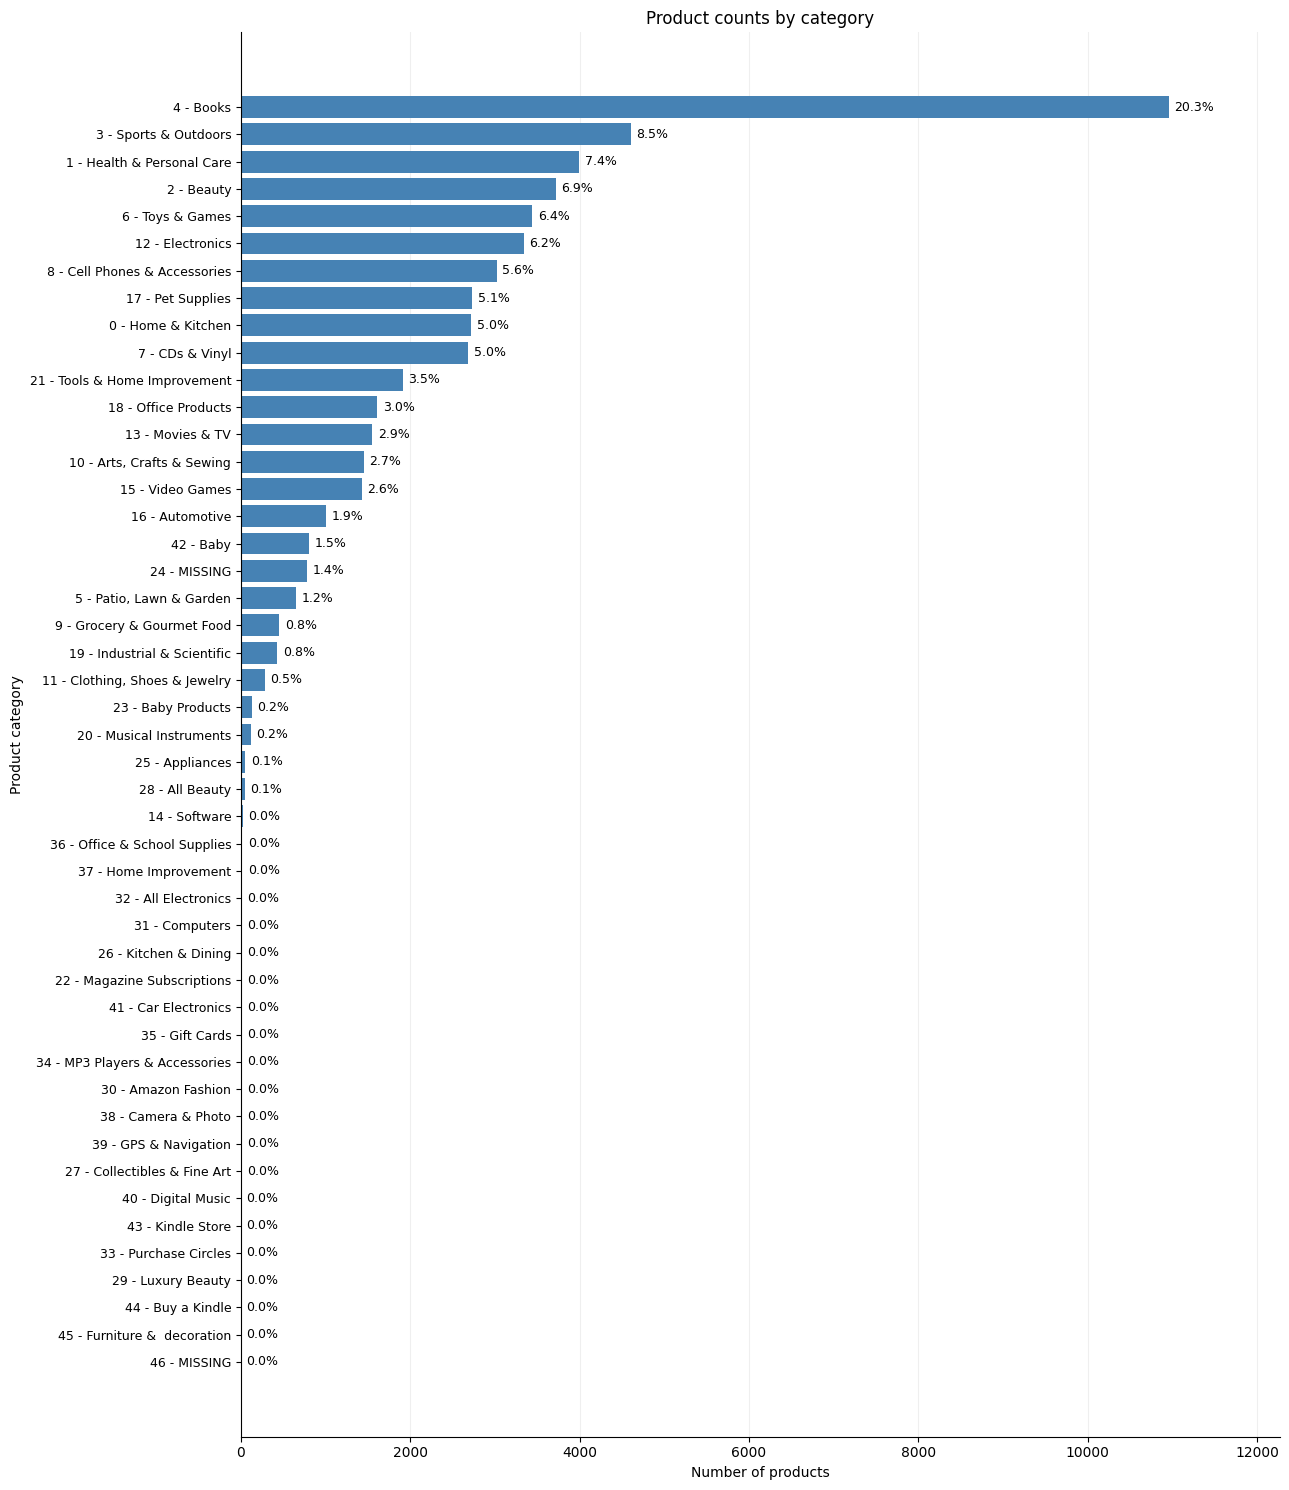

In [61]:
class_counts = nodes.label.value_counts().reindex(range(47), fill_value=0).sort_index()
class_table = class_counts.rename('nodes').to_frame().join(label_names)
class_table['fraction'] = class_table.nodes / n
class_by_split = pd.crosstab(nodes.label, nodes.split).reindex(index=range(47), fill_value=0)
class_table = class_table.join(class_by_split.add_prefix('split_'))
display(class_table)
present = class_counts[class_counts > 0]
print('Absent category IDs:', class_counts.index[class_counts == 0].tolist())
print('Largest/smallest observed class ratio:', round(present.max() / present.min(), 2))
# A majority baseline uses only training labels to choose its prediction.
majority_label = nodes.loc[split_masks['train'], 'label'].mode().iloc[0]
print('Training majority category:', majority_label)
print('Validation majority accuracy:', (labels[split_masks['valid']] == majority_label).mean())
# Change display labels only; retain numeric category IDs in the analysis tables.
category_tick_labels = {
    category_id: f'{category_id} - {label_names.loc[category_id]}'
    for category_id in class_counts.index
}

# Construct bar chart to show product category proportions
sorted_category_counts = class_counts.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(13, 15))
bars = ax.barh(range(len(sorted_category_counts)), sorted_category_counts.values,
               color='steelblue')
ax.set_yticks(range(len(sorted_category_counts)))
ax.set_yticklabels([category_tick_labels[i] for i in sorted_category_counts.index], fontsize=9)
ax.invert_yaxis()
ax.bar_label(bars,
             labels=[f'{100 * count / n:.1f}%' for count in sorted_category_counts.values],
             padding=4, fontsize=9)
ax.set(title='Product counts by category', xlabel='Number of products', ylabel='Product category')
ax.margins(x=0.12)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
eda_results_dir = PROJECT_ROOT / 'notebooks' / '0_eda' / 'eda_results'
eda_results_dir.mkdir(parents=True, exist_ok=True)
category_counts_jpg = eda_results_dir / 'product_counts_by_category.jpg'
fig.savefig(category_counts_jpg, dpi=300, bbox_inches='tight', facecolor='white')
print('Saved chart to:', category_counts_jpg)
plt.show()

Saved chart to: <repo>\notebooks\EDA\EDA results\category_proportions_within_each_split.jpg


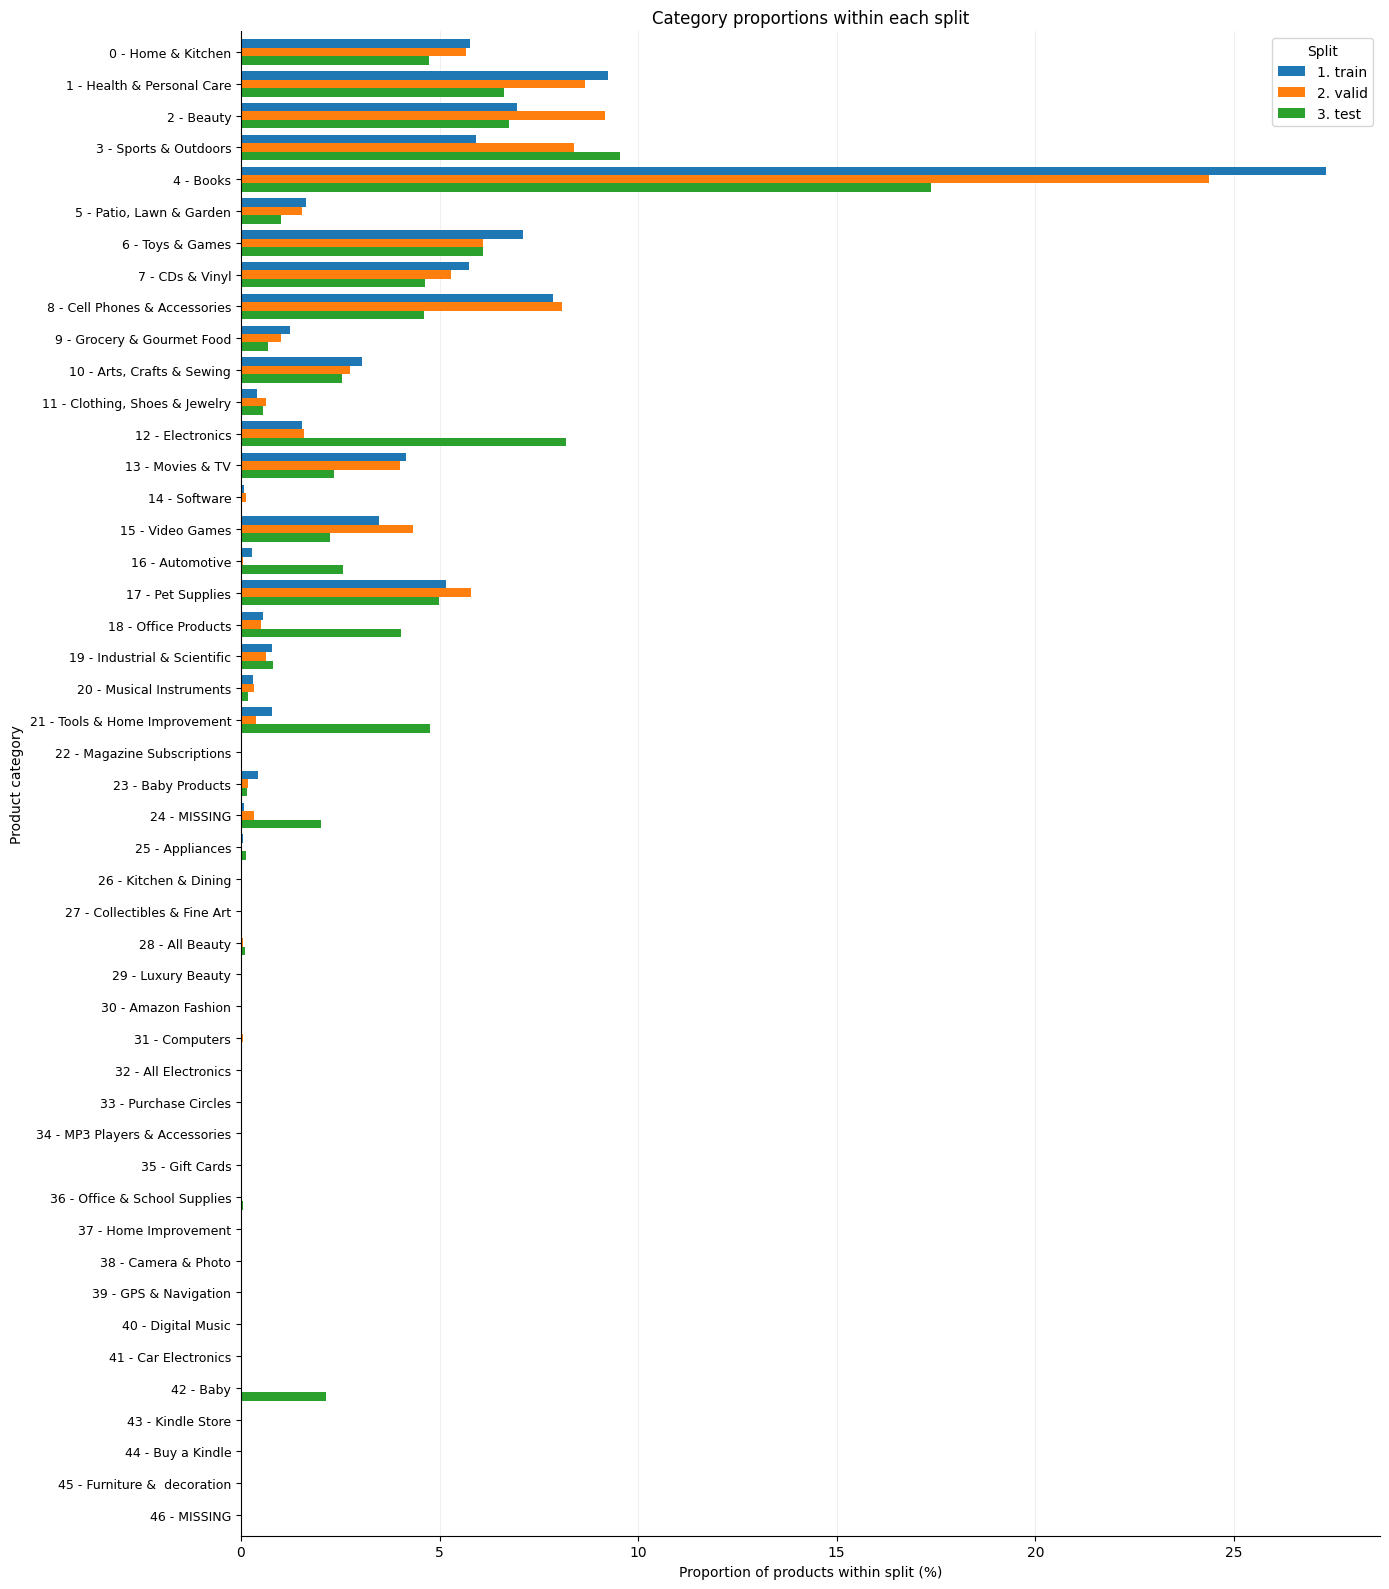

split
available_in_test     40
available_in_train    33
available_in_valid    26
dtype: int64

In [69]:
# Compare category composition within each split (each split sums to 100%).
split_proportions_pct = 100 * class_by_split.div(class_by_split.sum(axis=0), axis=1)
# Set display order explicitly without changing the underlying split names.
split_plot = split_proportions_pct.reindex(columns=['train', 'valid', 'test']).rename(
    index=category_tick_labels,
    columns={'train': '1. train', 'valid': '2. valid', 'test': '3. test'})
ax = split_plot.plot(
    kind='barh', title='Category proportions within each split', figsize=(14, 16),
    width=0.8, rot=0)
ax.invert_yaxis()
ax.set_xlabel('Proportion of products within split (%)')
ax.set_ylabel('Product category')
ax.tick_params(axis='y', labelsize=9)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
ax.legend(title='Split')
fig = ax.get_figure()
fig.tight_layout()
eda_results_dir = PROJECT_ROOT / 'notebooks' / '0_eda' / 'eda_results'
eda_results_dir.mkdir(parents=True, exist_ok=True)
split_proportions_jpg = eda_results_dir / 'category_proportions_within_each_split.jpg'
fig.savefig(split_proportions_jpg, dpi=300, bbox_inches='tight', facecolor='white')
print('Saved chart to:', split_proportions_jpg)
plt.show()

# display(class_by_split.eq(0).rename(columns=lambda s: f'absent_in_{s}'))
display(class_by_split.gt(0).rename(columns=lambda s: f'available_in_{s}').sum())


## 7. Text completeness, length, and duplicates

Audit titles and `content` (description) separately. Lengths below are whitespace word counts, **not LLM token counts**. Treat normalized duplicates as candidates for review, not evidence to delete products: different products may share descriptions. Missing values become empty strings only in derived text fields; original columns remain available.

### Clean text

In [47]:
text_quality = []
for field in ['title', 'content']:
    raw = nodes[field]
    clean = raw.fillna('').astype(str).str.strip()
    nodes[f'{field}_clean'] = clean
    nodes[f'{field}_chars'] = clean.str.len()
    nodes[f'{field}_words'] = clean.str.split().str.len()
    text_quality.append({'field': field, 'nulls': int(raw.isna().sum()),
                         'blank_including_nulls': int(clean.eq('').sum()),
                         'duplicate_nonblank_rows': int(clean[clean.ne('')].duplicated().sum())})
nodes['original_text'] = 'Product: ' + nodes.title_clean + '; Description: ' + nodes.content_clean
normalized_text = (nodes.title_clean + ' ' + nodes.content_clean).str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
nodes['text_fingerprint'] = normalized_text.map(lambda s: hashlib.sha256(s.encode('utf-8')).hexdigest())
display(pd.DataFrame(text_quality))
display(nodes[['title_chars', 'content_chars', 'title_words', 'content_words']].describe(
    percentiles=[.5, .9, .95, .99]))
display(nodes.groupby('split')[['title_words', 'content_words']].agg(['median', 'mean', 'max']))

print("\nUpdated nodes df:")
display(nodes.head(3))

,field,nulls,blank_including_nulls,duplicate_nonblank_rows
0,title,4903,4903,674
1,content,3846,3846,3251


,title_chars,content_chars,title_words,content_words
count,54025.000000,54025.000000,54025.000000,54025.000000
mean,58.505581,611.961870,9.165053,94.526478
std,45.443678,1000.367603,7.293681,128.693270
min,0.000000,0.000000,0.000000,0.000000
50%,52.000000,384.000000,8.000000,61.000000
90%,104.000000,1369.000000,16.000000,212.000000
95%,131.000000,1766.800000,21.000000,274.000000
99%,226.760000,3711.560000,36.000000,558.760000
max,863.000000,103990.000000,154.000000,9845.000000


title_words                content_words                  
           median      mean  max        median        mean   max
split                                                           
test          8.0  9.209326  154          59.0   89.484912  3538
train         8.0  9.098790  102          67.0  106.297185  9845
valid         8.0  8.722010   72          65.0  105.449109  2907


Updated nodes df:


,node_id,uid,nid,title,content,label,label_name,split,title_clean,title_chars,title_words,content_clean,content_chars,content_words,original_text,text_fingerprint
0,0,B00JXMX35K,1324660,"Aimee Gowns Original Bra-less Nursing Gown (X-Large, Fuchsia)",The one that started it all! The nightgown's modern design features a split front to help facilitate easy access to the breast for the baby. Simply pull asi...,11,"Clothing, Shoes & Jewelry",test,"Aimee Gowns Original Bra-less Nursing Gown (X-Large, Fuchsia)",61,8,The one that started it all! The nightgown's modern design features a split front to help facilitate easy access to the breast for the baby. Simply pull asi...,761,147,"Product: Aimee Gowns Original Bra-less Nursing Gown (X-Large, Fuchsia); Description: The one that started it all! The nightgown's modern design features a s...",ec35f391a668dfbaef585966e8d580cde97ceb69ecfe800fdff9c2a40e82ade1
1,1,B000XQHYFU,1670226,Casio DR-270TM 2-Color Professional Desktop Printing Calculator,Heavy duty printing,18,Office Products,test,Casio DR-270TM 2-Color Professional Desktop Printing Calculator,63,7,Heavy duty printing,19,3,Product: Casio DR-270TM 2-Color Professional Desktop Printing Calculator; Description: Heavy duty printing,70f303645d66a4bc909048d0f4106547668fc7a3411f7072e1470b4a1239f881
2,2,B00B67RO9Q,1780321,NaN,NaN,4,Books,test,,0,0,,0,0,Product: ; Description:,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855


### Check text distribution


Distribution of words:


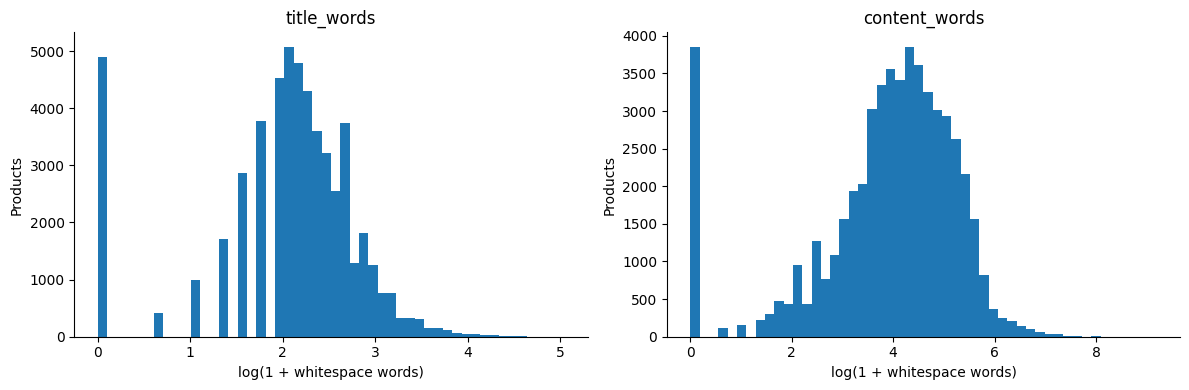


Sample records:


,node_id,label,split,title,content
37994,37994,7,train,Blackout,If you love energetic beats coupled with explosive lyrical content thenBlackout!is your album. This highly anticipated effort features the combined powers o...
27276,27276,4,test,"Never Kiss a Rake (Scandal at the House of Russell, Book One)",Stuart takes a break from paranormals and romantic thrillers (Risk the Night) to launch a historical romance series about three sisters unexpectedly orphane...
8310,8310,17,test,"Exo Terra Riverbed Sand, 10-Pound, Brown",Exo Terra riverbed sand is ideal for many types of aquatic turtles as it is their preferred substrate in the wild. Soft-shell turtles especially prefer the ...
35910,35910,42,test,Red Ninja Toddler Costume,"This costume includes shirt, hood, pants, and overvest."
27888,27888,12,test,"Bobj Rugged Case for Samsung Galaxy Tab3 10.1 Tablet, Models GT-P5200, GT-P5210, GT-P5220 - BobjGear protective cover (Bold Black)","This is an advanced design, high quality, protective silicone case for the Samsung Galaxy Tab3 10.1, Models GT-P5200, FT-P5210, GT-P5220. This is not a thin..."


In [48]:
# Distribution
print('\nDistribution of words:')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, field in zip(axes, ['title_words', 'content_words']):
    ax.hist(np.log1p(nodes[field]), bins=50)
    ax.set(title=field, xlabel='log(1 + whitespace words)', ylabel='Products')
plt.tight_layout(); plt.show()


# Samples
print("\nSample records:")
display(nodes[['node_id', 'label', 'split', 'title', 'content']].sample(min(5, n), random_state=SEED))

### Check duplicates

A text group contains products with identical normalised combined title + content; fully blank text is excluded. Cross-split groups and groups with different category labels are subsets of all duplicate groups and may overlap. Product counts below include **every product in the selected groups**, not only extra copies after the first. Cross-split counts cover all involved splits, not just test products. Do not add overlapping rows together.


In [66]:
nonblank = normalized_text.ne('')
duplicate_groups = nodes.loc[nonblank].groupby('text_fingerprint').agg(
    products=('node_id', 'size'), 
    splits=('split', 'nunique'), 
    labels=('label', 'nunique')
    )
is_duplicate = duplicate_groups['products'] > 1
is_cross_split = is_duplicate & (duplicate_groups['splits'] > 1)
is_conflicting = is_duplicate & (duplicate_groups['labels'] > 1)
group_selections = {
    'All duplicate text groups': is_duplicate,
    'Duplicate groups spanning multiple splits': is_cross_split,
    'Duplicate groups with different category labels': is_conflicting,
    'Groups both cross-split and differently labelled': is_cross_split & is_conflicting,
}
duplicate_summary_rows = []
for description, selected in group_selections.items():
    selected_groups = duplicate_groups.loc[selected]
    product_count = int(selected_groups['products'].sum())
    duplicate_summary_rows.append({
        'group_set': description,
        'text_groups': len(selected_groups),
        'products_in_groups': product_count,
        'percentage_of_all_products': 100 * product_count / len(nodes),
    })
duplicate_text_summary = pd.DataFrame(duplicate_summary_rows)
display(duplicate_text_summary.style.format({'percentage_of_all_products': '{:.2f}%'}))

display(duplicate_groups.query('products > 1').sort_values('products', ascending=False).head(10))

print("\nSamples of nodes with the same text groups:")
fingerprint = duplicate_groups.query('products > 1').index
display(nodes.loc[
    nodes['text_fingerprint'].isin(fingerprint),
    ['text_fingerprint', 'node_id', 'uid', 'title', 'content', 'label', 'split']
].sort_values(['text_fingerprint', 'node_id']).head()
)

print("\nSamples of nodes with the same text groups but with different labels:")
fingerprint = duplicate_groups.query('labels > 1').index
display(nodes.loc[
    nodes['text_fingerprint'].isin(fingerprint),
    ['text_fingerprint', 'node_id', 'uid', 'title', 'content', 'label', 'split']
].sort_values(['text_fingerprint', 'node_id']).head()
)

,group_set,text_groups,products_in_groups,percentage_of_all_products
0,All duplicate text groups,407,1037,1.92%
1,Duplicate groups spanning multiple splits,63,174,0.32%
2,Duplicate groups with different category labels,6,14,0.03%
3,Groups both cross-split and differently labelled,1,2,0.00%


,products,splits,labels
text_fingerprint,,,
1e5130f38863364b2a2d93fcc18d7abe8cd3fce719aa51fec00d9b545443e858,17,2,1
8be917c747293e6ae4abcc124e8af9d7d5b2d488b574cc48173c70a13e3be0bd,16,1,1
c035507f1dfaf2d3791555ca4f3bbf46b315e4072cafde4432aec934b94ed352,14,1,1
ab928532d7b28e731aaa58db44b7bc59b13606b1f40225efd500e5cee1d0ac2a,13,2,1
3ea28743ec1489fb9818a64fd1cd09a26167b99f84dc7451e177e68b0e4fa924,11,1,1
64ca3804a2a882c0ebf0fc42cd686f323de865884f067c5eb491c4c1cb654b60,11,1,1
677cdbebc5aece7323d2527fe7cb6799c8f969e4804c09b6e27c1dd806dfcfb9,10,1,1
39f0424da4b590f41a89ada814e4f1d15d5e094df79e66701c90380d2ecd7c2c,9,1,1
712e8cbe7b9b38ae1ac1f171a8230294b8500a4f47664c1409db0712d6b7e693,9,1,1



Samples of nodes with the same text groups:


,text_fingerprint,node_id,uid,title,content,label,split
4588,0021a073596f76253a5af9eaa49c26782057c1b21053d8af09d49d91a5972867,4588,B0052FSIPC,"Perricone MD Neuropeptide Facial Cleanser, 6 fl. oz.","A nourishing, conditioning and hydrating cream cleanser formulated with Dr. Perricone's advanced Neuropeptide technology. Non-drying and non-stripping, this...",2,test
23897,0021a073596f76253a5af9eaa49c26782057c1b21053d8af09d49d91a5972867,23897,B007C7A0UE,"Perricone MD Neuropeptide Facial Cleanser, 6 fl. oz.","A nourishing, conditioning and hydrating cream cleanser formulated with Dr. Perricone's advanced Neuropeptide technology. Non-drying and non-stripping, this...",2,test
49384,009458de748d8b026a5f43e8bb0a0461c58fa1a807727946c2214e5b65faeb49,49384,B009SAVH32,"Set of 4 Professional Laptop, LCD, iPad, iPod Spudgers Non-Mar Nylon and Metal Pry Open Repair Tools for Plastic Cell Phone, Tablet and MP3 Cases","The top tool is approx 6"" long and is a best seller. It is sold by Apple as part number 922-5065. The flat tip is 1/4"" wide and it is reinforced nylon and a...",12,test
49548,009458de748d8b026a5f43e8bb0a0461c58fa1a807727946c2214e5b65faeb49,49548,B00BHLVHVC,"Set of 4 Professional Laptop, LCD, iPad, iPod Spudgers Non-Mar Nylon and Metal Pry Open Repair Tools for Plastic Cell Phone, Tablet and MP3 Cases","The top tool is approx 6"" long and is a best seller. It is sold by Apple as part number 922-5065. The flat tip is 1/4"" wide and it is reinforced nylon and a...",12,test
11555,00d153e3add2bce9cccb0fef4389ffbc81336844323916eb9a902393bc5af6c2,11555,B00HRQAIYI,Blueberry Pet Pink Flamingo on Light Emerald Dog Collar,Our Pink Flaming Print Dog Collar is ideal for any pooch who likes to romp in the swamps of Miami and chase those long-legged birds! This jacquard-trimmed c...,17,test



Samples of nodes with the same text groups but with different labels:


,text_fingerprint,node_id,uid,title,content,label,split
5141,5627f2d820c4f7a016ee5d3621368bdc7082a7fa98bf4c30af49afff1c29a53f,5141,B00CR54ZZM,Spot Shot Professional Carpet Stain Remover - 3/18 oz.,Spot Shot Professional instantly powers out carpet stains and odors. No need for waiting or scrubbing. Just a quick blast and the toughest stains disappear ...,9,test
25883,5627f2d820c4f7a016ee5d3621368bdc7082a7fa98bf4c30af49afff1c29a53f,25883,B005067SAE,Spot Shot Professional Carpet Stain Remover - 3/18 oz.,Spot Shot Professional instantly powers out carpet stains and odors. No need for waiting or scrubbing. Just a quick blast and the toughest stains disappear ...,1,test
11893,a6b27623964b0bf77e52a8f2d66e6fcb2561dfe76357856563c0bd2bc24ba580,11893,B00CV920T2,NaN,NEW Combo BLUWAVS CD and FLAC FILE,20,test
11905,a6b27623964b0bf77e52a8f2d66e6fcb2561dfe76357856563c0bd2bc24ba580,11905,B005Q46HVG,NaN,NEW Combo BLUWAVS CD and FLAC FILE,7,test
26529,ae15beb807de18bc4b3d1acbc61bed2f1552e30576de0d0d86f7b9dee47bdebe,26529,B000NB3W7O,Boric Acid Powder - 12 Oz,"INDICATIONS: Boric Acid (100%) Powder is odorless and nonstaining. Boric Acid Powder kills roaches, water bugs, ants, fleas and silverfish. Boric Acid Powde...",3,train


In [50]:
# Text groups with multiple labels
duplicate_groups[duplicate_groups['labels']>1]

,products,splits,labels
text_fingerprint,,,
5627f2d820c4f7a016ee5d3621368bdc7082a7fa98bf4c30af49afff1c29a53f,2,1,2
a6b27623964b0bf77e52a8f2d66e6fcb2561dfe76357856563c0bd2bc24ba580,2,1,2
ae15beb807de18bc4b3d1acbc61bed2f1552e30576de0d0d86f7b9dee47bdebe,2,1,2
b79ada061ecda1f3b54994368df03bfd80fb1ac7a5644f88b056f1e9683d7be2,2,2,2
b7a7d0cd409ba66460af532be40bc2cf7fe3fb33437576c13bc4ecbb8995f2a2,4,1,2
fd550eb6ee12c30cffd5c06e0eef3c2626b21a90c590031df7cad54e26215917,2,1,2


## 8. Graph integrity, degree, and connected components

The release stores sparse adjacency `adj_t`. Inspect stored entries first, then canonicalize each pair to `(min_id, max_id)`, drop self-loops, and deduplicate. This defines a simple undirected graph for EDA without modifying the released object. Counts of sparse entries, directed pairs, and unique undirected edges are different quantities.

### Understanding the graph

In [51]:
adj = getattr(graph, 'adj_t', None)
adj

SparseTensor(row=tensor([    0,     0,     0,  ..., 13335, 13335, 13335]),
             col=tensor([  128,   129,   130,  ..., 54022, 54023, 54024]),
             size=(54025, 54025), nnz=74420, density=0.00%)

In [52]:
print(f"Dimensions:")
print(graph.adj_t.sparse_sizes())  # Matrix dimensions

print(f"\nStored entries (number of edges):")
print(graph.adj_t.nnz())          # Number of stored entries

row, col, values = graph.adj_t.coo()
print("\nUnderstanding the tensors:")
print(row, f"length: {len(row)}")
print(col, f"length: {len(col)}")

num_connections_to_show = 20
print(f'\nInspect first {num_connections_to_show} connections between nodes:')
print("Node 0 has connections to 15 other nodes")
i = 1
for r, c in zip(row[:num_connections_to_show].tolist(), col[:num_connections_to_show].tolist()):
    print(f"{i}) Node {r} ↔ Node {c}")
    i += 1

Dimensions:
(54025, 54025)

Stored entries (number of edges):
74420

Understanding the tensors:
tensor([    0,     0,     0,  ..., 13335, 13335, 13335]) length: 74420
tensor([  128,   129,   130,  ..., 54022, 54023, 54024]) length: 74420

Inspect first 20 connections between nodes:
Node 0 has connections to 15 other nodes
1) Node 0 ↔ Node 128
2) Node 0 ↔ Node 129
3) Node 0 ↔ Node 130
4) Node 0 ↔ Node 131
5) Node 0 ↔ Node 132
6) Node 0 ↔ Node 133
7) Node 0 ↔ Node 134
8) Node 0 ↔ Node 135
9) Node 0 ↔ Node 136
10) Node 0 ↔ Node 137
11) Node 0 ↔ Node 138
12) Node 0 ↔ Node 139
13) Node 0 ↔ Node 140
14) Node 0 ↔ Node 141
15) Node 0 ↔ Node 142
16) Node 1 ↔ Node 143
17) Node 1 ↔ Node 144
18) Node 1 ↔ Node 145
19) Node 1 ↔ Node 146
20) Node 1 ↔ Node 147


### Studying node 0 as an example
- Edges between 2 nodes show co-purchase relationships which means that these products have been brought together
- However, this edge alone does not show:
    - Whether the products are brought at the same time or different times (time gap between purchases)
    - How many customers bought both products and how often

In [53]:
display(text.iloc[[0]][['uid', 'title', 'content']])

print("\nIdentify label for node 0:")
label_0 = int(graph.y[0].item())
print(f"Node 0 label is {label_0} ({class_table.iloc[label_0, 1]})")

,uid,title,content
0,B00JXMX35K,"Aimee Gowns Original Bra-less Nursing Gown (X-Large, Fuchsia)",The one that started it all! The nightgown's modern design features a split front to help facilitate easy access to the breast for the baby. Simply pull asi...



Identify label for node 0:
Node 0 label is 11 (Clothing, Shoes & Jewelry)


### Identifying neighbours
- Identify neighbours of specified node
- It checks both endpoints, removes duplicate neighbours, and excludes self-loops

In [54]:
def identify_neighbours(node_i):
    neighbours = torch.unique(torch.cat([
        col[row == node_i],
        row[col == node_i],
    ]))
    neighbours = neighbours[neighbours != node_i]

    neighbour_ids = neighbours.cpu().tolist()
    neighbour_details = text.iloc[neighbour_ids][['uid', 'title']].copy()
    neighbour_details['label'] = graph.y[neighbour_ids].detach().cpu().numpy().reshape(-1)
    neighbour_details['category'] = neighbour_details['label'].map(label_names)

    print(f"Node {node_i}:")
    node_details = text.iloc[[node_i]][['uid', 'title', 'content']].copy()
    node_details['label'] = int(graph.y[node_i].item())
    node_details['category'] = node_details['label'].map(label_names)
    display(node_details)

    print(f"\nThere are {neighbours.numel()} neighbours of {node_i}:")
    display(neighbour_details)

identify_neighbours(0)

Node 0:


,uid,title,content,label,category
0,B00JXMX35K,"Aimee Gowns Original Bra-less Nursing Gown (X-Large, Fuchsia)",The one that started it all! The nightgown's modern design features a split front to help facilitate easy access to the breast for the baby. Simply pull asi...,11,"Clothing, Shoes & Jewelry"



There are 15 neighbours of 0:


,uid,title,label,category
128,B009UPUJIY,Munchkin 3 Count Waterproof Changing Pad Liners,23,Baby Products
129,B001MS83OE,Summer Infant 4-Sided Changing Pad,42,Baby
130,B002MCD16O,Medtech Laboratories Dermoplast - 2.75oz - Model 115-7882 - Each,1,Health & Personal Care
131,B0049O6RXM,"Boppy Cottony Cute 2-Sided Slipcover, Polka Stripe Pink",42,Baby
132,B00BH0OKI0,"NuRoo Pocket Skin to Skin (Medium, Teal)",42,Baby
133,B008KJQMA0,"WaterWipes Super Value Box Baby Wipes, 9 packs of 60 Count | 540 baby wipes",23,Baby Products
134,B000VPTHP8,Tucks Medicated Cooling Pads 100 Pads Per Pack (Pack of 2),1,Health & Personal Care
135,B0006GWSTO,Dermoplast First Aid Spray 2.75 Oz Aerosol Can,1,Health & Personal Care
136,B00F0T8WWE,"Safety 1st Deluxe Healthcare and Grooming Kit, Dupont Circle",42,Baby
137,0761152121,"What to Expect the First Year, Second Edition",4,Books


### Summarising the graph

In [55]:
adj = getattr(graph, 'adj_t', None)
# Refresh the node count in case exploratory cells changed n in this kernel.
n = int(graph.num_nodes)
if adj is not None:
    if tuple(adj.sparse_sizes()) != (n, n):
        raise ValueError('Adjacency dimensions disagree with node count.')
    row, col, _ = adj.coo()
    stored_pairs = np.column_stack([as_numpy(row), as_numpy(col)]).astype(np.int64)
else:
    edge_index = getattr(graph, 'edge_index', None)
    if edge_index is None or not hasattr(edge_index, 'shape') or edge_index.shape[0] != 2:
        raise ValueError('No supported adj_t or [2, E] edge_index found.')
    stored_pairs = as_numpy(edge_index).T.astype(np.int64)
assert ((stored_pairs >= 0) & (stored_pairs < n)).all(), 'Edge endpoint outside subset.'
self_loops = int((stored_pairs[:, 0] == stored_pairs[:, 1]).sum())
directed_unique = np.unique(stored_pairs, axis=0)
undirected = np.unique(np.sort(stored_pairs, axis=1), axis=0)
undirected = undirected[undirected[:, 0] != undirected[:, 1]]
u, v = undirected.T
m = len(undirected)
print(f"undirected length: {m}")
degree = np.bincount(undirected.ravel(), minlength=n) # Count how many neighbours each node has
print(f"degree length: {len(degree)}")

nodes['degree'] = degree
symmetric = np.array_equal(directed_unique, np.unique(directed_unique[:, ::-1], axis=0))
adjacency = coo_matrix((np.ones(2*m, dtype=np.int8),
                        (np.r_[u, v], np.r_[v, u])), shape=(n, n)).tocsr()
num_components, component_id = connected_components(adjacency, directed=False)
component_sizes = np.bincount(component_id)
graph_summary = pd.Series({
    'nodes': n, 'stored_entries': len(stored_pairs), 'unique_directed_pairs': len(directed_unique),
    'stored_self_loops': self_loops, 'duplicate_stored_pairs': len(stored_pairs)-len(directed_unique),
    'stored_adjacency_symmetric': bool(symmetric), 'unique_undirected_edges_no_loops': m,
    'isolated_nodes': int((degree == 0).sum()), 'mean_degree': float(degree.mean()),
    'median_degree': float(np.median(degree)), 'max_degree': int(degree.max()),
    'connected_components': int(num_components), 'largest_component_nodes': int(component_sizes.max()),
    'largest_component_fraction': float(component_sizes.max()/n),
    'undirected_density': 2*m/(n*(n-1)) if n > 1 else 0,
}, name='value')
display(graph_summary.to_frame())

undirected length: 72319
degree length: 54025


,value
nodes,54025
stored_entries,74420
unique_directed_pairs,74420
stored_self_loops,0
duplicate_stored_pairs,0
stored_adjacency_symmetric,False
unique_undirected_edges_no_loops,72319
isolated_nodes,1
mean_degree,2.677242
median_degree,1.0


### Checking degrees and neighbours

In [56]:
degree_counts = (
    pd.Series(degree)
    .value_counts()
    .sort_index()
    .rename_axis('degree')
    .reset_index(name='node_count')
)

degree_counts['proportion_pct'] = (
    degree_counts['node_count'] / degree_counts['node_count'].sum() * 100
).round(2)

display(degree_counts)

,degree,node_count,proportion_pct
0,0,1,0.00
1,1,36002,66.64
2,2,3584,6.63
3,3,819,1.52
4,4,303,0.56
5,5,968,1.79
6,6,6747,12.49
7,7,2125,3.93
8,8,927,1.72
9,9,488,0.90


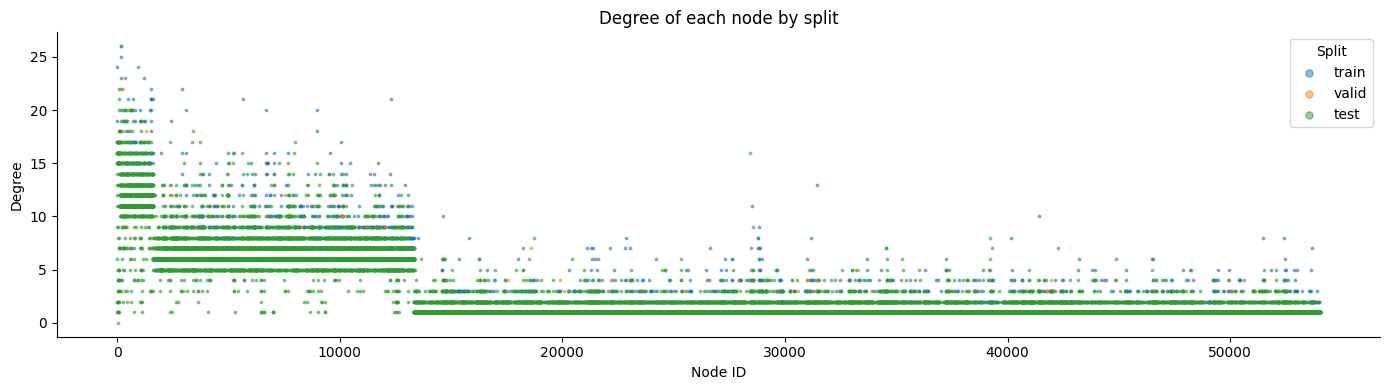

In [57]:
fig, ax = plt.subplots(figsize=(14, 4))

for split in ['train', 'valid', 'test']:
    subset = nodes.loc[nodes['split'].eq(split)]
    ax.scatter(subset['node_id'], subset['degree'],
               s=3, alpha=0.5, label=split)

ax.set(xlabel='Node ID', ylabel='Degree',
       title='Degree of each node by split')
ax.legend(title='Split', markerscale=3)
plt.tight_layout()
plt.show()

In [58]:
identify_neighbours(21045)
identify_neighbours(3772)

Node 21045:


,uid,title,content,label,category
21045,B0047LO2FM,4GB Black mini Clip Mp3 player,"This is an Amazing 4GB mp3 player .This item doesnt work with itunes, does not syncronize and does not belong to Apple. this works as a removable disk and y...",12,Electronics



There are 1 neighbours of 21045:


,uid,title,label,category
3772,B006DX0K0I,Purple Mini metal Clip MP3 Player supports 2GB 4GB 8GB Micro SD TF Card,12,Electronics


Node 3772:


,uid,title,content,label,category
3772,B006DX0K0I,Purple Mini metal Clip MP3 Player supports 2GB 4GB 8GB Micro SD TF Card,Mini Clip MP3 Player w/ Head Phones and Micro SD TF Card Reader for up to 8GB (2GB - 8GB). We have the following colors available: Purple Red Pink Black Whi...,12,Electronics



There are 8 neighbours of 3772:


,uid,title,label,category
403,B0095SLKRK,MUSIC ANGEL Mini Speaker Micro SD/TF USB MP3 MP4 Ipod FM Radio LCD A08 pink,12,Electronics
406,B00A8GY5VG,TD-V26 Portable Mini Digital Speaker with Micro SD / TF / USB /FM - Pink,12,Electronics
408,B00A8GY59I,Portable Mini Digital Speaker with Micro Sd / Tf / USB /Fm (Blue),12,Electronics
20972,B004QYM55O,2 GB MicroSD Memory Card (Bulk Packaged),12,Electronics
21042,B004OQLEPG,White USB Charger Dock Cradle for Ipod apple,12,Electronics
21043,B000X9BF3E,Solar-powered LED Flashlight w/ Keychain,21,Tools & Home Improvement
21044,B00EKEVTF2,Sannysis2008 Sport Black/Blue Wireless Headphones Music MP3 Player TF Card FM Radio Headset,3,Sports & Outdoors
21045,B0047LO2FM,4GB Black mini Clip Mp3 player,12,Electronics



Proposal comparison: approximately 74k edges; measured unique undirected edges: 72319


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,37745.0,2.606067,2.874299,0.0,1.0,1.0,4.0,26.0
train,14708.0,2.871363,3.237401,1.0,1.0,1.0,5.0,26.0
valid,1572.0,2.569975,2.881635,1.0,1.0,1.0,2.0,22.0


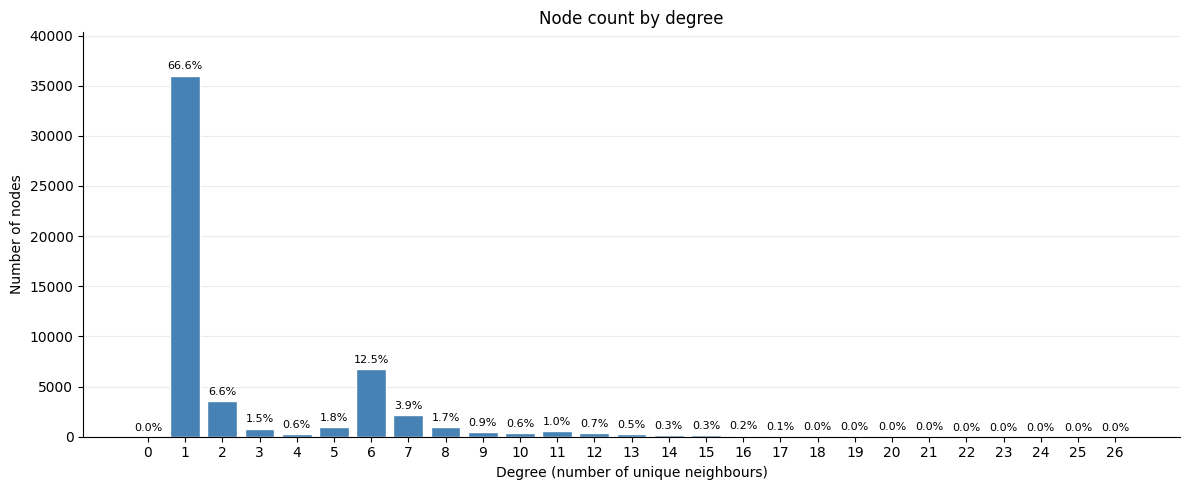


Nodes with highest degree:


,node_id,title,label,split,degree
163,163,Muay Thai MMA Ankle Support Wraps (Pair),3,train,26
172,172,Shock Doctor Adult Pro Strapless Mouthguard (Smoke),3,test,26
162,162,180&quot; Elastic Cotton MMA Handwraps (Pair),3,train,25
16,16,"3 Packs of HTC Evo 4G Anti-Glare, Reduced Fingerprints - Matte Finishing Screen Protector",8,train,24
938,938,"""Printed Kraft Paper / Wrapping Paper, 30&quot; x 10' Rolls, Pack of 3, prints may vary (dog paw print, balloons, pink/chocolate bubbles, white filigree, go...",1,test,24


In [59]:
print('\nProposal comparison: approximately 74k edges; measured unique undirected edges:', m)
display(nodes.groupby('split').degree.describe())

# Exact counts at each integer degree, including isolated nodes (degree 0).
degree_counts = (nodes['degree'].value_counts()
                 .reindex(range(int(nodes['degree'].max()) + 1), fill_value=0)
                 .sort_index())
assert int(degree_counts.sum()) == len(nodes)
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(degree_counts.index, degree_counts.values, color='steelblue', edgecolor='white')
percent_labels = [f'{100 * count / len(nodes):.1f}%' for count in degree_counts.values]
ax.bar_label(bars, labels=percent_labels, padding=3, fontsize=8)
ax.margins(y=0.12)
ax.set(xlabel='Degree (number of unique neighbours)', ylabel='Number of nodes',
       title='Node count by degree', xticks=degree_counts.index)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print('\nNodes with highest degree:')
display(nodes.nlargest(5, 'degree')[['node_id', 'title', 'label', 'split', 'degree']])

## 9. Homophily and edges between splits

**Homophily is the tendency for connected nodes to have similar properties.** In this notebook, it measures whether connected products have the **same category label**.

For example, consider these **hypothetical** edges:

| Connected products | Same category? |
|---|---|
| Two baby-care products, both labelled Baby | Yes |
| Two books, both labelled Books | Yes |
| A nursing gown labelled Clothing, Shoes & Jewelry and wipes labelled Baby Products | No |

**Edge homophily** = number of unique undirected edges connecting products with the same label / total number of unique undirected edges.

If 70 out of 100 edges connect products with the same category, edge homophily is **0.70, or 70%**. The calculation below excludes self-loops.

**Node homophily** is the fraction of a particular node's neighbours sharing its label. A node with no neighbours has undefined node homophily and is excluded from the reported mean. Averaging node homophily gives each non-isolated node equal weight, so it can differ from edge homophily.

This matters because GNNs combine information from neighbours:
- High label homophily can make neighbouring features useful for category prediction. 
- However, **different-category neighbours can still provide useful context**, such as nursing supplies connected to a nursing gown. 
- Homophily here uses exact category IDs, so products that seem related in everyday terms may still count as having different labels.

The squared class-frequency sum is a simple independent-label reference, not a degree-corrected significance test. Also report the endpoint-frequency reference because high-degree classes may be overrepresented.

Full-graph label homophily is a retrospective diagnostic. Restrict any label-based model selection to training nodes. Cross-split edges alone are expected in transductive evaluation.

### Summary of homophily checks

**Training-only mean node homophily: 81.49%.** This averages over 7,689 training products with training neighbours; 7,019 training products have none and are excluded.

The values below describe the observed release; rerun the calculation if the dataset changes.

| Metric | Meaning | Observed result |
|---|---|---|
| `edge_homophily_all_labels` | Fraction of all unique undirected edges connecting products with the same category label. | **79.50%** of connected pairs share a label. |
| `mean_node_homophily_excluding_isolates` | For each node, calculate the fraction of neighbours sharing its label, then average across nodes with neighbours. Each node receives equal weight. | On average, **78.97%** of a node's neighbours share its label. |
| `independent_node_label_reference` | Probability that two products drawn independently and uniformly from all nodes have the same label, based on category proportions. | **8.26%** provides a baseline reflecting class imbalance. |
| `independent_endpoint_label_reference` | Same-label probability under independent draws from the distribution of edge endpoints. Higher-degree products have more influence because they appear on more edges. | **8.17%** provides a baseline accounting for category frequencies at edge endpoints. |
| `train_induced_edges` | Number of unique undirected edges for which both endpoints are training nodes. | **7,082 edges**. |
| `train_induced_edge_homophily` | Fraction of those training-to-training edges connecting products with the same label. | **81.56%** of training-to-training pairs share a label. |
| `train_induced_mean_node_homophily_excluding_isolates` | For each training product with at least one training neighbour, calculate the fraction of its training neighbours sharing its label, then average equally across these products. Validation/test neighbours are excluded. | **81.49%**, averaged across **7,689 training products**. The other **7,019 training products** have no training neighbours and are excluded. |

**Why the two homophily averages differ:** edge homophily weights every edge equally; mean node homophily weights every non-isolated node equally.

**Key finding:**
- The graph's **78.97% mean node homophily** indicates strong same-category neighbour similarity. The **8.26% independent-node-label reference** is a descriptive comparison reflecting class proportions, not a topology-aware null model. 
- Within the training-only subgraph, **81.49% mean node homophily** shows that this pattern also holds using training labels alone. This differs from the **81.56% training edge homophily**, which weights edges rather than products equally. 
- It does not guarantee improved accuracy, and these reference values are not statistical significance tests.

The full-graph metrics use validation and test labels too, so treat them as descriptive EDA; use training labels for label-based modelling decisions.

In [34]:
same_label = labels[u] == labels[v]
edge_homophily = float(same_label.mean()) if m else np.nan
class_frequency = np.bincount(labels, minlength=47) / n
endpoint_counts = np.bincount(np.r_[labels[u], labels[v]], minlength=47)
endpoint_frequency = endpoint_counts / (2*m) if m else np.zeros(47)
same_neighbours = np.bincount(np.r_[u[same_label], v[same_label]], minlength=n)
nodes['node_homophily'] = np.divide(same_neighbours, degree,
    out=np.full(n, np.nan), where=degree > 0)
train_edges = split_masks['train'][u] & split_masks['train'][v]

# Node homophily in the subgraph containing only training nodes.
train_degree = np.bincount(np.r_[u[train_edges], v[train_edges]], minlength=n)
train_same_edges = train_edges & same_label
train_same_neighbours = np.bincount(
    np.r_[u[train_same_edges], v[train_same_edges]], minlength=n)
train_node_homophily = np.divide(
    train_same_neighbours, train_degree,
    out=np.full(n, np.nan), where=train_degree > 0)
train_has_neighbours = split_masks['train'] & (train_degree > 0)
train_without_neighbours = split_masks['train'] & (train_degree == 0)
train_mean_node_homophily = (
    float(train_node_homophily[train_has_neighbours].mean())
    if train_has_neighbours.any() else np.nan)
assert int(train_degree.sum()) == 2 * int(train_edges.sum())

homophily_summary = pd.Series({
    'edge_homophily_all_labels': edge_homophily,
    'mean_node_homophily_excluding_isolates': nodes.node_homophily.mean(),
    'independent_node_label_reference': float((class_frequency**2).sum()),
    'independent_endpoint_label_reference': float((endpoint_frequency**2).sum()),
    'train_induced_edges': int(train_edges.sum()),
    'train_induced_mean_node_homophily_excluding_isolates': train_mean_node_homophily,
    'train_nodes_with_training_neighbours': int(train_has_neighbours.sum()),
    'train_nodes_without_training_neighbours': int(train_without_neighbours.sum()),
    'train_induced_edge_homophily': float(same_label[train_edges].mean()) if train_edges.any() else np.nan,
}, name='value')
display(homophily_summary.to_frame())
print(f'Training-only mean node homophily: {train_mean_node_homophily:.2%}')
print(f'Training products included: {train_has_neighbours.sum():,}; excluded: {train_without_neighbours.sum():,}')


,value
edge_homophily_all_labels,0.794992
mean_node_homophily_excluding_isolates,0.789713
independent_node_label_reference,0.082635
independent_endpoint_label_reference,0.081726
train_induced_edges,7082.000000
train_induced_mean_node_homophily_excluding_isolates,0.814900
train_nodes_with_training_neighbours,7689.000000
train_nodes_without_training_neighbours,7019.000000
train_induced_edge_homophily,0.815589


Training-only mean node homophily: 81.49%
Training products included: 7,689; excluded: 7,019


### Studying homophily by product categories
- The table below shows how strongly products in each category connect to products with the same category label
- Neighbour information may work differently across categories. 
    - For Books, neighbours often reinforce the same label. 
    - Clothing has an average degree of 2.87 but low homophily: its products have neighbours, but those neighbours often have different labels. Neighbours may provide related usage context without sharing the label.

In [29]:
grouped = nodes.groupby('label').agg(
    products=('node_id', 'size'),
    mean_degree=('degree', 'mean'), 
    median_degree=('degree', 'median'), 
    mean_node_homophily=('node_homophily', 'mean')
    ).reset_index()
grouped = grouped.merge(label_mapping, on='label', how='left')
display(grouped[['label', 'label_name', 'products', 'mean_degree', 'median_degree', 'mean_node_homophily']])

,label,label_name,products,mean_degree,median_degree,mean_node_homophily
0,0,Home & Kitchen,2721,2.518192,1.0,0.712437
1,1,Health & Personal Care,3994,2.719329,1.0,0.744271
2,2,Beauty,3718,2.928725,1.0,0.843322
3,3,Sports & Outdoors,4605,2.858198,1.0,0.763867
4,4,Books,10956,2.568456,1.0,0.938509
5,5,"Patio, Lawn & Garden",649,2.691834,1.0,0.653028
6,6,Toys & Games,3441,2.517873,1.0,0.715921
7,7,CDs & Vinyl,2682,2.655108,1.0,0.967140
8,8,Cell Phones & Accessories,3019,2.832726,1.0,0.833023
9,9,Grocery & Gourmet Food,455,1.635165,1.0,0.443979


### Category prevalence versus node homophily

Each point represents an observed category. The horizontal axis is its proportion of all products; the vertical axis is the mean fraction of same-category neighbours across its non-isolated products. The proportion axis uses a logarithmic scale to separate rare categories while retaining the largest categories in the same plot.

Labels identify the eight largest categories, with a key below. The dashed horizontal line is the overall mean node homophily. Category proportions alone do not determine homophily: compare categories at similar prevalence and consider their product counts. Rare-category estimates can be unstable. These full-label plots are descriptive EDA, not inputs for model selection.


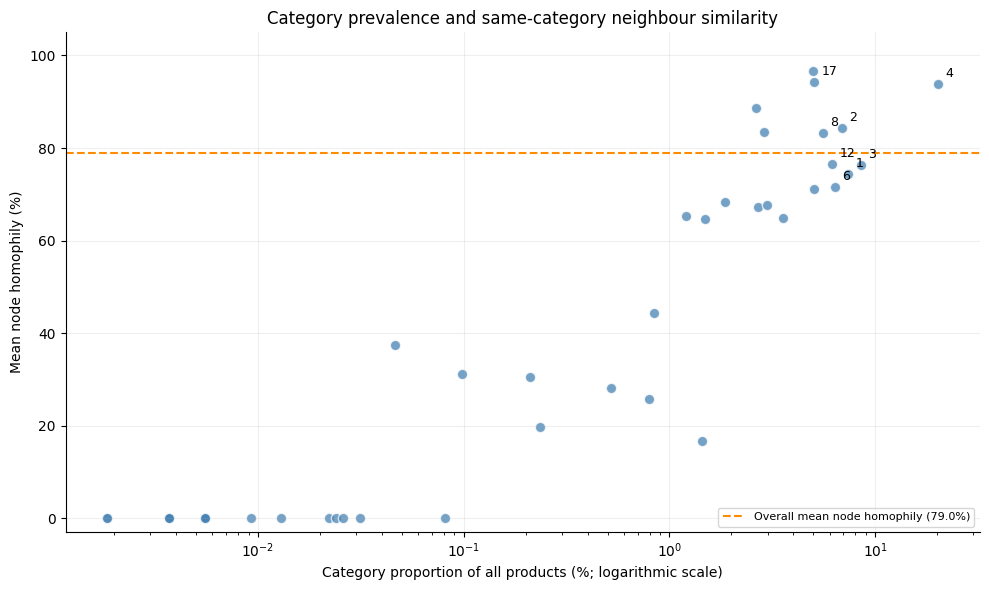

Key for labelled categories; all observed categories are plotted:


,label,label_name,products,proportion_pct,mean_node_homophily
1,1,Health & Personal Care,3994,7.392874,0.744271
2,2,Beauty,3718,6.881999,0.843322
3,3,Sports & Outdoors,4605,8.523832,0.763867
4,4,Books,10956,20.279500,0.938509
6,6,Toys & Games,3441,6.369273,0.715921
8,8,Cell Phones & Accessories,3019,5.588154,0.833023
12,12,Electronics,3338,6.178621,0.766335
17,17,Pet Supplies,2730,5.053216,0.942830


In [31]:
category_homophily = grouped[['label', 'label_name', 'products', 'mean_node_homophily']].copy()
category_homophily['proportion_pct'] = 100 * category_homophily['products'] / len(nodes)
plot_categories = category_homophily.dropna(subset=['mean_node_homophily'])
label_categories = plot_categories.nlargest(8, 'products')
overall_node_homophily_pct = 100 * nodes['node_homophily'].mean()

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(plot_categories['proportion_pct'],
           100 * plot_categories['mean_node_homophily'],
           s=55, alpha=0.75, color='steelblue', edgecolors='white')
ax.axhline(overall_node_homophily_pct, color='darkorange', linestyle='--',
           label=f'Overall mean node homophily ({overall_node_homophily_pct:.1f}%)')
for row in label_categories.itertuples():
    ax.annotate(str(row.label), (row.proportion_pct, 100 * row.mean_node_homophily),
                xytext=(5, 5), textcoords='offset points', fontsize=9)
ax.set_xscale('log')
ax.set(xlabel='Category proportion of all products (%; logarithmic scale)',
       ylabel='Mean node homophily (%)', ylim=(-3, 105),
       title='Category prevalence and same-category neighbour similarity')
ax.grid(alpha=0.2)
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()
print('Key for labelled categories; all observed categories are plotted:')
display(label_categories[['label', 'label_name', 'products', 'proportion_pct',
                          'mean_node_homophily']].sort_values('label'))


### Co-purchased products with different categories

The examples below are actual edges in the released graph connecting products with different category IDs. Products can serve related or complementary purposes without belonging to the same category: a nursing gown and changing-pad liners, for example. Such edges count against label homophily but are not automatically erroneous or uninformative.

These pairs are selected illustrations, not a representative sample or proof that one product caused the other purchase. Titles and category names are read directly from the dataset; every selected edge is checked below.


In [70]:
import html

# Fixed subset node IDs make the selected examples reproducible.
example_pairs = [(0, 128), (0, 137), (1, 143), (3, 160), (6, 211)]
undirected_edge_set = set(zip(u.tolist(), v.tolist()))
example_nodes = nodes.set_index('node_id')
cross_category_rows = []
for first, second in example_pairs:
    assert tuple(sorted((first, second))) in undirected_edge_set, 'Pair must be an actual graph edge'
    product_a, product_b = example_nodes.loc[first], example_nodes.loc[second]
    label_a, label_b = int(product_a['label']), int(product_b['label'])
    assert label_a != label_b, 'Example must connect different category IDs'
    cross_category_rows.append({
        'node_a': first, 'product_a': html.unescape(str(product_a['title'])),
        'category_a': f'{label_a} - {label_names.loc[label_a]}',
        'node_b': second, 'product_b': html.unescape(str(product_b['title'])),
        'category_b': f'{label_b} - {label_names.loc[label_b]}',
    })
cross_category_examples = pd.DataFrame(cross_category_rows)
with pd.option_context('display.max_colwidth', None):
    display(cross_category_examples)
cross_category_export_dir = PROJECT_ROOT / 'notebooks' / '0_eda' / 'eda_results'
cross_category_export_dir.mkdir(parents=True, exist_ok=True)
cross_category_examples.to_csv(cross_category_export_dir / 'cross_category_co_purchase_examples.csv', index=False)
print('Verified each pair is a unique undirected connection between different category labels.')


,node_a,product_a,category_a,node_b,product_b,category_b
0,0,"Aimee Gowns Original Bra-less Nursing Gown (X-Large, Fuchsia)","11 - Clothing, Shoes & Jewelry",128,Munchkin 3 Count Waterproof Changing Pad Liners,23 - Baby Products
1,0,"Aimee Gowns Original Bra-less Nursing Gown (X-Large, Fuchsia)","11 - Clothing, Shoes & Jewelry",137,"What to Expect the First Year, Second Edition",4 - Books
2,1,Casio DR-270TM 2-Color Professional Desktop Printing Calculator,18 - Office Products,143,Logitech Wireless Mouse M310 (Silver),12 - Electronics
3,3,Muay Thai Shorts-Black,"11 - Clothing, Shoes & Jewelry",160,"PRO IMPACT Boxing/MMA Handwraps 180"" Mexican Style Elastic 1 Pair BLACK",3 - Sports & Outdoors
4,6,"Cable Matters 2-Pack, Gold Plated 3.5mm Stereo Audio Cable in Black 6 Feet",12 - Electronics,211,Arturia MicroBrute Analog Synthesizer,20 - Musical Instruments


Verified each pair is a unique undirected connection between different category labels.


### Studying cross-split edges

**1. Understanding transductive setup**

"Transductive" means that the model can see the graph it will eventually make predictions on, including:
- All products’ input features, such as text embeddings.
- All graph connections.
- Training products’ category labels.

Validation and test labels are withheld from the training loss. Validation labels are used separately for model selection; test labels are reserved for final evaluation.

An inductive setup, by comparison, evaluates predictions for previously unseen nodes or graphs that were unavailable during training.

**2. Why a cross-split edge is not automatically label leakage?**
- An edge communicates a relationship between A and B but it does not reveal B’s category label. A GNN can use this relationship to combine A’s features with B’s features.
- Although predictions are computed for every node, only training labels directly supervise the parameter updates as training typically applies the loss only to training nodes.
- Leakage would only occur if test labels entered the loss, or were included in node features or prompts, or were used to choose model settings.

**3. Node participation**

All nodes can participate in graph computation, but only training nodes provide labels for learning.

| What is used during training? | Train nodes | Validation/test nodes |
|---|---|---|
| Input features | Yes | Yes |
| Edges and message passing | Yes | Yes |
| True labels in the training loss | **Yes** | **No** |

For this dataset, the GNN can process **all 54,025 nodes**, but the supervised training loss uses only the **14,708 training nodes**. Validation labels are used separately for model selection, and test labels are reserved for final evaluation.

In [157]:
split_pairs = np.sort(np.column_stack([nodes.split.to_numpy()[u], nodes.split.to_numpy()[v]]), axis=1)
split_edges = pd.DataFrame(split_pairs, columns=['split_a', 'split_b']).value_counts().rename('edges').reset_index()
display(split_edges)

,split_a,split_b,edges
0,test,test,34533
1,test,train,26734
2,train,train,7082
3,test,valid,2566
4,train,valid,1334
5,valid,valid,70


## 10. Degree slices and cold-start preparation

Low degree is a structural proxy, not proof that a listing is new. Fixed slices make later MLP/GCN error comparisons reproducible. This cell reports how many test edges would be removed by the proposal's cold-start scenario (remove **all** edges incident to test products), without altering the graph. Actual inference and accuracy drops belong in the experiments notebook.

In [11]:
nodes['degree_slice'] = pd.cut(nodes.degree, bins=[-1, 0, 2, 5, 10, np.inf],
    labels=['0 (isolated)', '1-2', '3-5', '6-10', '11+'])
degree_slices = pd.crosstab(nodes.degree_slice, nodes.split, dropna=False)
display(degree_slices)
display(nodes.groupby('degree_slice', observed=False).agg(products=('node_id', 'size'),
    mean_content_words=('content_words', 'mean'), mean_node_homophily=('node_homophily', 'mean')))
test_mask = split_masks['test']
remove_at_cold_start = test_mask[u] | test_mask[v]
print('Undirected edges removed:', int(remove_at_cold_start.sum()), 'of', m)
print('Test products already isolated:', int((test_mask & (degree == 0)).sum()))
print('Test products losing neighbours:', int((test_mask & (degree > 0)).sum()))

split,test,train,valid
degree_slice,,,
0 (isolated),1,0,0
1-2,27821,10581,1184
3-5,1491,541,58
6-10,7376,2958,289
11+,1056,628,41


,products,mean_content_words,mean_node_homophily
degree_slice,,,
0 (isolated),1,83.000000,NaN
1-2,39586,94.785454,0.786831
3-5,2090,92.686124,0.814872
6-10,10623,94.308011,0.794402
11+,1725,92.165217,0.796481


Undirected edges removed: 63833 of 72319
Test products already isolated: 1
Test products losing neighbours: 37744


## 11. Optional TAPE explanation coverage (later arms G/H)

Initial EDA needs no explanations. For later comparison, download the **ogbn-products LLM responses** from the [official README](https://github.com/XiaoxinHe/TAPE#b-llm-responses) and extract JSON files to `data/TAPE/gpt_responses/ogbn-products/` in this repository. Do not confuse `gpt_preds/ogbn-products.csv` (predicted labels) with explanation text.

The official loader reads `<subset_node_id>.json` and `choices[0].message.content`. Check missing/empty responses before joining them by subset node ID. Generated explanations may explicitly contain predicted categories; audit them separately from label-free product extraction.

In [12]:
RESPONSE_DIR = DATA_DIR / 'gpt_responses' / 'ogbn-products'
if not RESPONSE_DIR.exists():
    print('Optional explanation archive not present; skipping coverage audit.')
else:
    response_audit = []
    for node_id in range(n):
        path = RESPONSE_DIR / f'{node_id}.json'
        status, chars = 'missing', 0
        if path.exists():
            try:
                obj = json.loads(path.read_text(encoding='utf-8'))
                response = obj['choices'][0]['message']['content']
                if not isinstance(response, str):
                    raise TypeError('Response content is not a string')
                chars = len(response.strip())
                status = 'ok' if chars else 'empty'
            except (ValueError, KeyError, IndexError, TypeError, UnicodeError):
                status = 'invalid'
        response_audit.append((node_id, status, chars))
    response_audit = pd.DataFrame(response_audit, columns=['node_id', 'status', 'chars'])
    display(response_audit.status.value_counts())
    display(response_audit.query("status != 'ok'").head(10))

Optional explanation archive not present; skipping coverage audit.


## 12. Optional export and EDA notes

Turn on exports only after reviewing the checks. Export diagnostic metadata, class/split counts, summaries, and environment versions. Labels and split metadata must remain separate from the inputs sent to the extraction LLM. Raw text and the graph remain unchanged.

In [13]:
EXPORT_EDA = False
if EXPORT_EDA:
    output_dir = DATA_DIR / 'eda'
    output_dir.mkdir(exist_ok=True)
    nodes[['node_id', 'label', 'split', 'degree', 'degree_slice', 'node_homophily',
           'title_words', 'content_words', 'text_fingerprint']].to_csv(output_dir / 'node_diagnostics.csv', index=False)
    class_table.to_csv(output_dir / 'class_counts.csv')
    split_summary.to_csv(output_dir / 'split_summary.csv')
    graph_summary.to_csv(output_dir / 'graph_summary.csv')
    homophily_summary.to_csv(output_dir / 'homophily_summary.csv')
    degree_slices.to_csv(output_dir / 'degree_slices.csv')
    packages = ['numpy', 'pandas', 'matplotlib', 'scipy', 'torch', 'torch-geometric', 'torch-sparse']
    versions = {p: importlib.metadata.version(p) for p in packages}
    (output_dir / 'environment.json').write_text(json.dumps(
        {'python': platform.python_version(), 'packages': versions, 'commit': COMMIT, 'seed': SEED}, indent=2), encoding='utf-8')
    print('Exported to:', output_dir)
else:
    print('Exports disabled. Set EXPORT_EDA=True when ready.')

Exports disabled. Set EXPORT_EDA=True when ready.


### Findings to fill in after running

| Topic | Observation | Implication / action |
|---|---|---|
| Verified node/class/edge counts | Pending execution | Reconcile any difference with proposal; record edge convention |
| Released splits and class coverage | Pending execution | Freeze split; flag missing training categories |
| Missing/blank/duplicate text | Pending execution | Define conservative cleaning; review cross-split duplicates |
| Text length tails | Pending execution | Choose encoder truncation using training/validation data |
| Degree and isolates | Pending execution | Keep fixed degree slices for model error analysis |
| Homophily | Pending execution | Contextualize graph gains without assuming causality |
| Explanation coverage | Optional / pending | Ensure G/H use aligned released responses |

### Next steps tied to the proposal

- Build a ~500-product extraction pilot using **training products**; send only titles/descriptions, never labels or released explanations, to the local extraction LLM.
- Audit ~50 extractions for product type, brand, key attributes, and hallucinations; log actual tokenizer counts and runtime.
- Compute frozen text embeddings, then compare original/extracted/TAPE explanation features and random-vector capacity controls on the same masks.
- Compare MLP and GCN; later add GraphSAGE and test-edge removal at inference. Report accuracy and macro-F1 over at least three seeds.
- Extend homophily analysis with embedding similarities, including a clearly defined comparison before/after extraction.

No numerical findings are claimed until these cells are executed on the real release.